## Baseline training script

### Imports

In [1]:
import sys
from pathlib import Path

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import lightning.pytorch as pl
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data import CLASS_NAMES, BloodDataModule

print(f"PyTorch:   {torch.__version__}")
print(f"Lightning: {pl.__version__}")
print(f"CUDA:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device:    {torch.cuda.get_device_name(0)}")

PyTorch:   2.14.1+cu126
Lightning: 2.6.6
CUDA:      True
Device:    NVIDIA GeForce RTX 3050 Laptop GPU


### Data initialisation

In [2]:
dm = BloodDataModule(batch_size=64, use_augmentations=True, grayscale=False, num_workers=0)
dm.setup()

print(f"Train samples: {len(dm.train_dataset):,}")
print(f"Val samples:   {len(dm.val_dataset):,}")
print(f"Test samples:  {len(dm.test_dataset):,}")
print(f"Channels:      {dm.in_channels}")
print(f"Train mean:    {np.round(dm.train_mean, 4)}")
print(f"Train std:     {np.round(dm.train_std, 4)}")

print("\nClass counts and weights (train):")
counts = dm.class_counts.numpy()
weights = dm.class_weights.numpy()
for idx, (name, c, w) in enumerate(zip(CLASS_NAMES, counts, weights)):
    print(f"  [{idx}] {name:<20}: count={c:5d} ({c / len(dm.train_dataset) * 100:5.2f}%), weight={w:.4f}")

Train samples: 11,959
Val samples:   1,712
Test samples:  3,421
Channels:      3
Train mean:    [0.8162 0.6685 0.6955]
Train std:     [0.2152 0.2415 0.1175]

Class counts and weights (train):
  [0] Basophil            : count=  852 ( 7.12%), weight=1.4975
  [1] Eosinophil          : count= 2181 (18.24%), weight=0.5850
  [2] Erythroblast        : count= 1085 ( 9.07%), weight=1.1759
  [3] Immature Granulocyte: count= 2026 (16.94%), weight=0.6298
  [4] Lymphocyte          : count=  849 ( 7.10%), weight=1.5028
  [5] Monocyte            : count=  993 ( 8.30%), weight=1.2849
  [6] Neutrophil          : count= 2330 (19.48%), weight=0.5476
  [7] Platelet            : count= 1643 (13.74%), weight=0.7766


In [3]:
batch_x, batch_y = next(iter(dm.train_dataloader()))

print(f"batch_x: shape={batch_x.shape}, dtype={batch_x.dtype}, range=[{batch_x.min():.2f}, {batch_x.max():.2f}]")
print(f"batch_y: shape={batch_y.shape}, dtype={batch_y.dtype}")
print(f"labels:  {batch_y[:10].tolist()}")

batch_x: shape=torch.Size([64, 3, 28, 28]), dtype=torch.float32, range=[-5.92, 2.59]
batch_y: shape=torch.Size([64]), dtype=torch.int64
labels:  [7, 3, 6, 5, 6, 6, 2, 3, 2, 1]


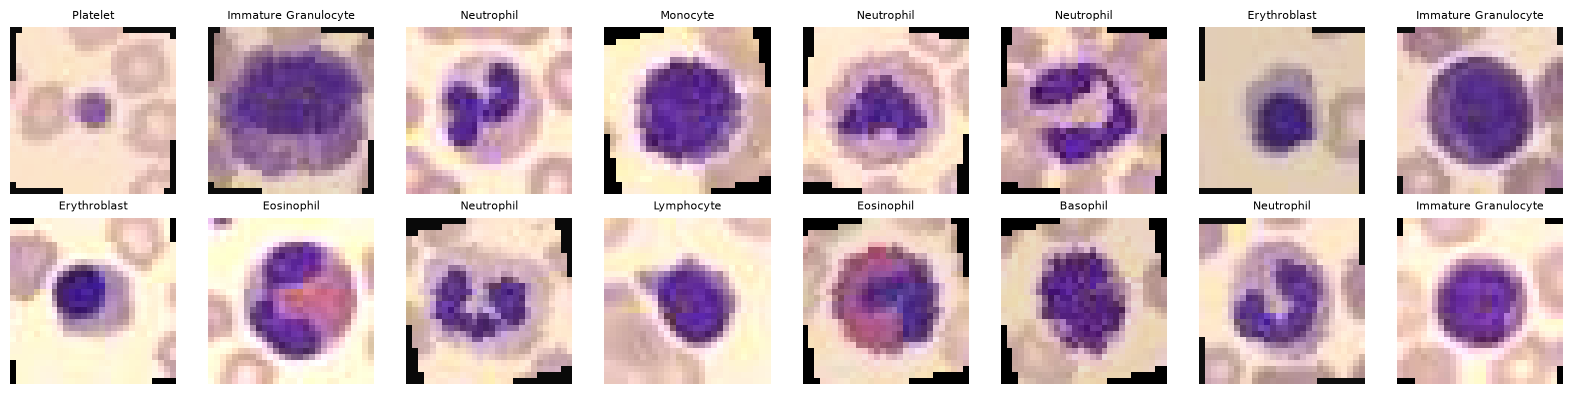

In [4]:
def denormalize(tensor, mean, std):
    img = tensor.clone().detach().cpu()
    mean_t = torch.tensor(mean).view(-1, 1, 1)
    std_t = torch.tensor(std).view(-1, 1, 1)
    img = img * std_t + mean_t
    return torch.clamp(img, 0.0, 1.0).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flatten()):
    img = denormalize(batch_x[i], dm.train_mean, dm.train_std)
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[batch_y[i]], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Model Architecture & Baseline Initialization 


In [5]:
from src.model import BloodClassifier, BloodNet

# Instantiate baseline model
model = BloodClassifier(
    in_channels=dm.in_channels,
    num_classes=dm.num_classes,
    base_channels=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-4,
    optimizer_name="adamw",
    scheduler_name="cosine",
    max_epochs=20,
    class_weights=None,  # Unweighted baseline; weighted loss can be evaluated in HPO / ablations
)

print(model)

BloodClassifier(
  (net): BloodNet(
    (block1): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, st

In [6]:
# Compute and display model parameter counts
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters:     102,248
Trainable parameters: 102,248


In [7]:
# Verify forward pass on the sample batch from DataLoader
model.eval()
with torch.no_grad():
    sample_logits = model(batch_x)
    sample_preds = torch.argmax(sample_logits, dim=-1)
    sample_loss = model.loss_fn(sample_logits, batch_y)

print(f"Batch input shape:   {batch_x.shape}")
print(f"Logits output shape: {sample_logits.shape} (expected [{batch_x.shape[0]}, {dm.num_classes}])")
print(f"Sample initial loss: {sample_loss.item():.4f}")
print(f"Initial predictions: {sample_preds[:8].tolist()}")
print(f"Ground truth labels: {batch_y[:8].tolist()}")

Batch input shape:   torch.Size([64, 3, 28, 28])
Logits output shape: torch.Size([64, 8]) (expected [64, 8])
Sample initial loss: 2.0618
Initial predictions: [1, 1, 1, 1, 1, 1, 1, 1]
Ground truth labels: [7, 3, 6, 5, 6, 6, 2, 3]


## Phase 3: Baseline Training & Experiment Tracking

In [8]:
import os
from lightning.pytorch.callbacks import (
    EarlyStopping,
    LearningRateMonitor,
    ModelCheckpoint,
)
from lightning.pytorch.loggers import CSVLogger, WandbLogger
import wandb

PROJECT_NAME = "mlops-lab-1-bloodmnist"
RUN_NAME = "baseline-convnet-rgb"
LOG_DIR = Path("../logs").resolve()
CHECKPOINT_DIR = Path("../checkpoints/baseline").resolve()

LOG_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

wandb_mode = "online" if os.environ.get("WANDB_API_KEY") or getattr(wandb.api, "api_key", None) else "offline"
wandb_logger = WandbLogger(
    project=PROJECT_NAME,
    name=RUN_NAME,
    save_dir=str(LOG_DIR),
    log_model=False,
    mode=wandb_mode,
)
print(f"WandB Logger initialized in [{wandb_mode.upper()}] mode (run: {RUN_NAME})")

csv_logger = CSVLogger(
    save_dir=str(LOG_DIR),
    name="baseline",
)

checkpoint_callback = ModelCheckpoint(
    dirpath=str(CHECKPOINT_DIR),
    filename="best-baseline-{epoch:02d}-{val_f1_macro:.4f}",
    monitor="val_f1_macro",
    mode="max",
    save_top_k=1,
    save_last=True,
    verbose=True,
)

early_stopping_callback = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    verbose=True,
)

lr_monitor = LearningRateMonitor(logging_interval="epoch")

wandb: WARNING wandb.api and wandb.ensure_configured() are deprecated and will be removed in a future release. To check for credentials without prompting, use wandb.login(prompt=False).


WandB Logger initialized in [OFFLINE] mode (run: baseline-convnet-rgb)


In [9]:
MAX_EPOCHS = 20

trainer = pl.Trainer(
    max_epochs=MAX_EPOCHS,
    accelerator="auto",
    devices=1,
    logger=[wandb_logger, csv_logger],
    callbacks=[checkpoint_callback, early_stopping_callback, lr_monitor],
    log_every_n_steps=20,
    deterministic=False,
)

print("Starting baseline model training...")
trainer.fit(model, datamodule=dm)

print("\nTraining completed successfully!")
print(f"Best checkpoint path:  {checkpoint_callback.best_model_path}")
print(f"Best validation score: {checkpoint_callback.best_model_score:.4f} (val_f1_macro)")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 3050 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.


Starting baseline model training...


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode | FLOPs
----------------------------------------------------------------
0 | net       | BloodNet           | 102 K  | eval | 0    
1 | loss_fn   | CrossEntropyLoss   | 0      | eval | 0    
2 | train_f1  | MulticlassF1Score  | 0      | eval | 0    
3 | train_acc | MulticlassAccuracy | 0      | eval | 0    
4 | val_f1    | MulticlassF1Score  | 0      | eval | 0    
5 | val_acc   | MulticlassAccuracy | 0      | eval | 0    
6 | test_f1   | MulticlassF1Score  | 0      | eval | 0    
7 | test_acc  | MulticlassAccuracy | 0      | eval | 0    
----------------------------------------------------------------
102 K     Trainable params
0         Non-trainable params
102 K     Total params
0.409     Total estimated model params size (MB)
0         Modules in train mode
31        Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/mnt/c/St

Training: |          | 0/? [00:00<?, ?it/s]

... (37 outputs left out)

Metric val_loss improved by 0.011 >= min_delta = 0.0. New best score: 0.249
Epoch 18, global step 3553: 'val_f1_macro' reached 0.90588 (best 0.90588), saving model to '/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/baseline/best-baseline-epoch=18-val_f1_macro=0.9059.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.248
Epoch 19, global step 3740: 'val_f1_macro' was not in top 1
`Trainer.fit` stopped: `max_epochs=20` reached.



Training completed successfully!
Best checkpoint path:  /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/baseline/best-baseline-epoch=18-val_f1_macro=0.9059.ckpt
Best validation score: 0.9059 (val_f1_macro)


In [10]:
test_results = trainer.test(model, datamodule=dm, ckpt_path="best")

print("\n=== Test Set Benchmark Summary ===")
for k, v in test_results[0].items():
    print(f"  {k:<16}: {v:.4f}")

Restoring states from the checkpoint path at /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/baseline/best-baseline-epoch=18-val_f1_macro=0.9059.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/baseline/best-baseline-epoch=18-val_f1_macro=0.9059.ckpt
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `Data

Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.8912452459335327
      test_f1_macro         0.8952062129974365
        test_loss           0.2577734589576721
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

=== Test Set Benchmark Summary ===
  test_loss       : 0.2578
  test_f1_macro   : 0.8952
  test_acc        : 0.8912


### Learning Verification & Curve Analysis

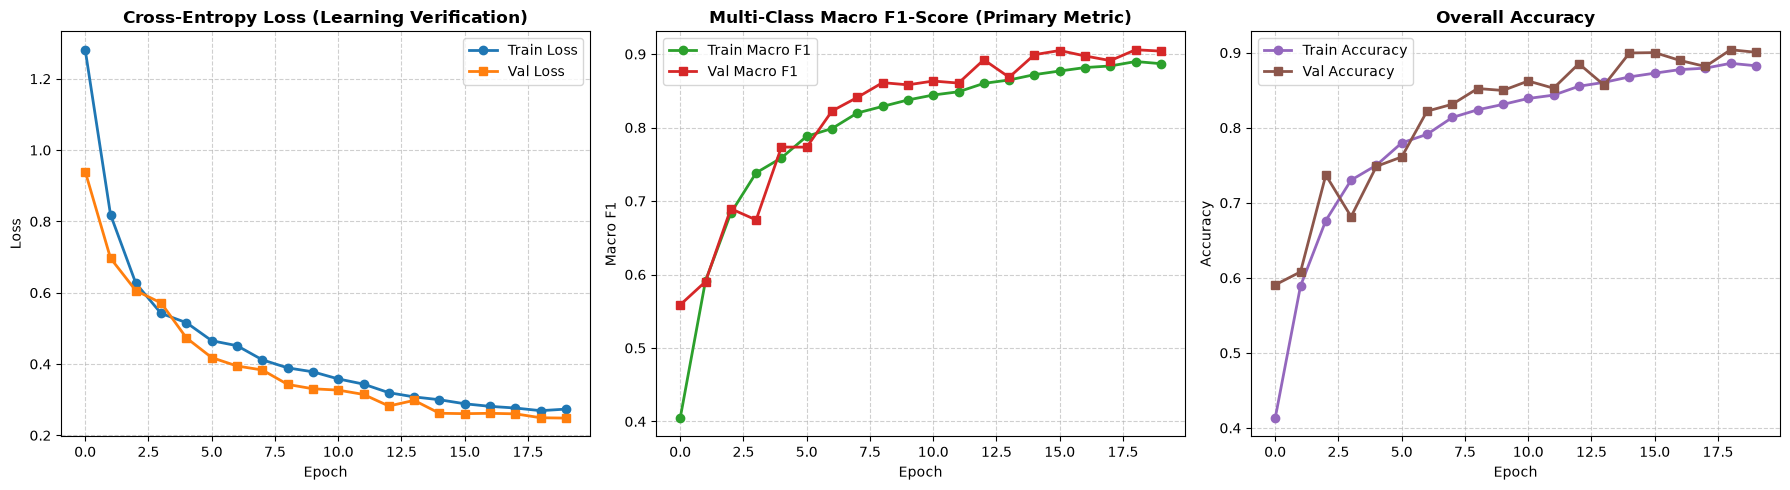

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

metrics_path = Path(csv_logger.log_dir) / "metrics.csv"
if metrics_path.exists():
    df_raw = pd.read_csv(metrics_path)
    
    df_epochs = df_raw.groupby("epoch", as_index=False).mean(numeric_only=True)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    if "train_loss" in df_epochs.columns and "val_loss" in df_epochs.columns:
        axes[0].plot(df_epochs["epoch"], df_epochs["train_loss"], label="Train Loss", marker="o", color="#1f77b4", linewidth=2)
        axes[0].plot(df_epochs["epoch"], df_epochs["val_loss"], label="Val Loss", marker="s", color="#ff7f0e", linewidth=2)
        axes[0].set_title("Cross-Entropy Loss (Learning Verification)", fontsize=12, fontweight="bold")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].grid(True, linestyle="--", alpha=0.6)
        axes[0].legend()

    if "train_f1_macro" in df_epochs.columns and "val_f1_macro" in df_epochs.columns:
        axes[1].plot(df_epochs["epoch"], df_epochs["train_f1_macro"], label="Train Macro F1", marker="o", color="#2ca02c", linewidth=2)
        axes[1].plot(df_epochs["epoch"], df_epochs["val_f1_macro"], label="Val Macro F1", marker="s", color="#d62728", linewidth=2)
        axes[1].set_title("Multi-Class Macro F1-Score (Primary Metric)", fontsize=12, fontweight="bold")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].grid(True, linestyle="--", alpha=0.6)
        axes[1].legend()

    if "train_acc" in df_epochs.columns and "val_acc" in df_epochs.columns:
        axes[2].plot(df_epochs["epoch"], df_epochs["train_acc"], label="Train Accuracy", marker="o", color="#9467bd", linewidth=2)
        axes[2].plot(df_epochs["epoch"], df_epochs["val_acc"], label="Val Accuracy", marker="s", color="#8c564b", linewidth=2)
        axes[2].set_title("Overall Accuracy", fontsize=12, fontweight="bold")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("Accuracy")
        axes[2].grid(True, linestyle="--", alpha=0.6)
        axes[2].legend()

    plt.tight_layout()
    plt.show()
else:
    print(f"Metrics file not found at {metrics_path}. Please inspect curves in the WandB dashboard.")

### Confusion Matrix & Per-Class Breakdown


Loading best model checkpoint: /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/baseline/best-baseline-epoch=18-val_f1_macro=0.9059.ckpt

=== Per-Class Classification Report (Test Set) ===

                      precision    recall  f1-score   support

            Basophil     0.7895    0.7992    0.7943       244
          Eosinophil     0.9872    0.9872    0.9872       624
        Erythroblast     0.9385    0.9325    0.9355       311
Immature Granulocyte     0.7781    0.8359    0.8060       579
          Lymphocyte     0.8945    0.8724    0.8833       243
            Monocyte     0.8502    0.7394    0.7910       284
          Neutrophil     0.9655    0.9655    0.9655       666
            Platelet     1.0000    0.9979    0.9989       470

            accuracy                         0.9117      3421
           macro avg     0.9004    0.8912    0.8952      3421
        weighted avg     0.9129    0.9117    0.9118      3421



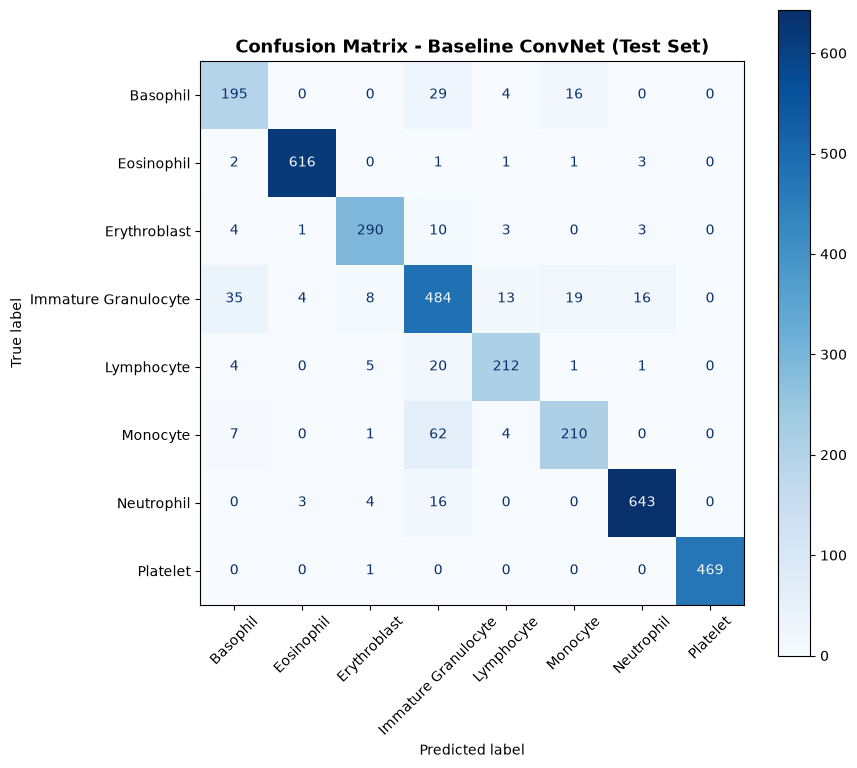

epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇██
lr-AdamW,████▇▇▇▆▆▅▄▄▃▃▂▂▂▁▁▁
test_acc,▁
test_f1_macro,▁
test_loss,▁
train_acc,▁▄▅▆▆▆▇▇▇▇▇▇████████
train_f1_macro,▁▄▅▆▆▇▇▇▇▇▇▇████████
train_loss,█▅▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
val_acc,▁▁▄▃▅▅▆▆▇▇▇▇█▇██████
+2,...


In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

best_checkpoint_path = checkpoint_callback.best_model_path
print(f"Loading best model checkpoint: {best_checkpoint_path}")
best_model = BloodClassifier.load_from_checkpoint(best_checkpoint_path)
best_model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model = best_model.to(device)

all_preds = []
all_targets = []

with torch.no_grad():
    for x_batch, y_batch in dm.test_dataloader():
        x_batch = x_batch.to(device)
        logits = best_model(x_batch)
        preds = torch.argmax(logits, dim=-1).cpu()
        all_preds.extend(preds.numpy())
        all_targets.extend(y_batch.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

print("\n=== Per-Class Classification Report (Test Set) ===\n")
print(classification_report(all_targets, all_preds, target_names=CLASS_NAMES, digits=4))

# 2. Confusion matrix visualization
cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix - Baseline ConvNet (Test Set)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

if wandb.run is not None:
    wandb.finish()